In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display

simulator = AerSimulator()

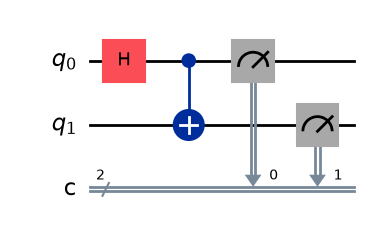

In [2]:
qc_original = QuantumCircuit(2, 2)

qc_original.h(0)
qc_original.cx(0, 1)
qc_original.measure([0, 1], [0, 1])

display(qc_original.draw('mpl'))

Original results: {'00': 56, '11': 44}


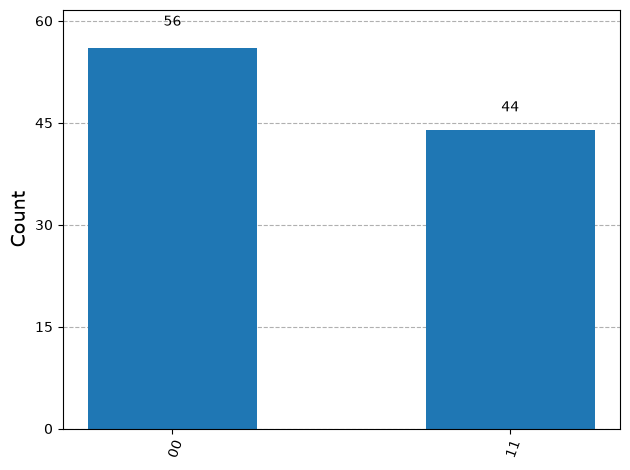

In [3]:
result_original = simulator.run(
    qc_original, shots=100
).result()

counts_original = result_original.get_counts()

print("Original results:", counts_original)
display(plot_histogram(counts_original))

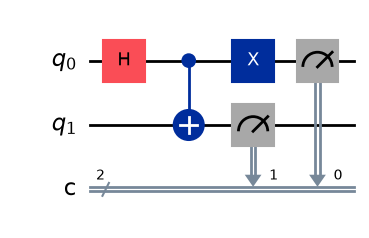

In [4]:
qc_modified = QuantumCircuit(2, 2)

qc_modified.h(0)
qc_modified.cx(0, 1)
qc_modified.x(0)
qc_modified.measure([0, 1], [0, 1])

display(qc_modified.draw('mpl'))

Modified results: {'01': 52, '10': 48}


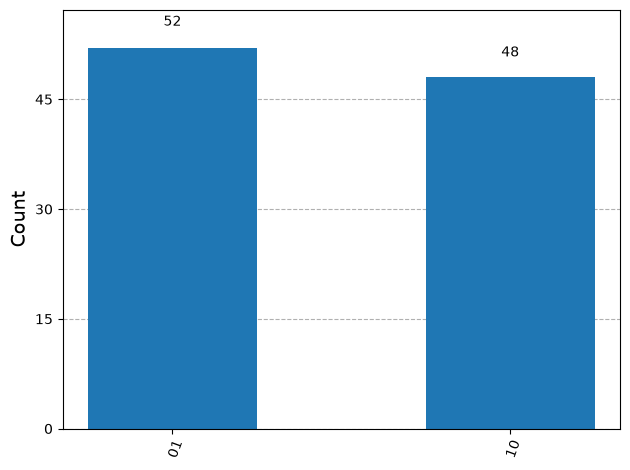

In [5]:
result_modified = simulator.run(
    qc_modified, shots=100
).result()

counts_modified = result_modified.get_counts()

print("Modified results:", counts_modified)
display(plot_histogram(counts_modified))

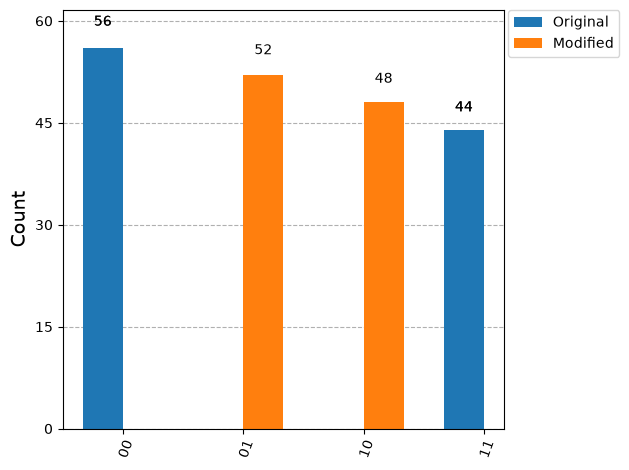

In [6]:
display(plot_histogram(
    [counts_original, counts_modified],
    legend=['Original', 'Modified']
))

## Challenge 3: Can You Change the Correlation?

### Predictions
- Original circuit: Outcomes 00 and 11 are expected to dominate.
- Modified circuit: Outcomes 01 and 10 are expected to dominate.

### Observation
The original circuit produces correlated outcomes, mainly 00 and 11. After adding an X gate to the first qubit, the modified circuit produces opposite outcomes, mainly 01 and 10.

### Conclusion
The X gate flips the first qubit, changing the measurement outcomes from matching values to opposite values. The histograms demonstrate this change.